In [1]:
import numpy as np

# Données
X = np.array([
    [2, 1],
    [3, 2],
    [4, 3],
    [5, 4]
])

# Directions
w1 = np.array([1, 1]) / np.sqrt(2)
w2 = np.array([1, -1]) / np.sqrt(2)

# Projection scalaire (x . w)
proj_w1 = X @ w1
proj_w2 = X @ w2

print("Projection sur w1 = (1,1):")
print(proj_w1)

print("\nProjection sur w2 = (1,-1):")
print(proj_w2)

Projection sur w1 = (1,1):
[2.12132034 3.53553391 4.94974747 6.36396103]

Projection sur w2 = (1,-1):
[0.70710678 0.70710678 0.70710678 0.70710678]


Vecteurs directeurs : vA = [1. 1.]  vB = [ 1 -1]
Scalaires le long de A: [2.12132034 3.53553391 4.94974747 6.36396103]
Scalaires le long de B: [0.70710678 0.70710678 0.70710678 0.70710678]
Distances orthogonales à A: [0.70710678 0.70710678 0.70710678 0.70710678]
Distances orthogonales à B: [2.12132034 3.53553391 4.94974747 6.36396103]
Proportion variance expliquée par A: 1.0
Proportion variance expliquée par B: 0.0


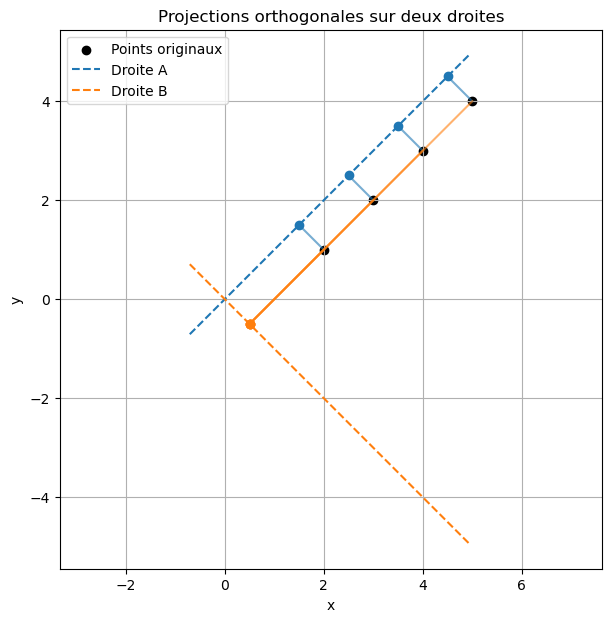

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Data
X = np.array([
    [2, 1],
    [3, 2],
    [4, 3],
    [5, 4]
])

# Définir deux droites par leurs vecteurs directeurs
vA = np.array([1.0, 1.0])
angle_deg = 10.0
rad = np.deg2rad(angle_deg)
vB = np.array([1,-1])

def project_points_onto_direction(X, v):
    u = v / np.linalg.norm(v)
    scalars = X.dot(u)
    projections = np.outer(scalars, u)
    return projections, scalars

projA, scalarsA = project_points_onto_direction(X, vA)
projB, scalarsB = project_points_onto_direction(X, vB)

# Évaluations
distsA = np.linalg.norm(X - projA, axis=1)
distsB = np.linalg.norm(X - projB, axis=1)

total_var = np.var(X, axis=0).sum()
explained_prop_A = np.var(scalarsA) / total_var
explained_prop_B = np.var(scalarsB) / total_var

print("Vecteurs directeurs : vA =", vA, " vB =", vB)
print("Scalaires le long de A:", scalarsA)
print("Scalaires le long de B:", scalarsB)
print("Distances orthogonales à A:", distsA)
print("Distances orthogonales à B:", distsB)
print("Proportion variance expliquée par A:", explained_prop_A)
print("Proportion variance expliquée par B:", explained_prop_B)

# Tracé
plt.figure(figsize=(7,7))
plt.scatter(X[:,0], X[:,1], color='black', label='Points originaux')

t = np.linspace(-1, 7, 100)
uA = vA / np.linalg.norm(vA)
uB = vB / np.linalg.norm(vB)
lineA = np.outer(t, uA)
lineB = np.outer(t, uB)
plt.plot(lineA[:,0], lineA[:,1], '--', color='C0', label='Droite A')
plt.plot(lineB[:,0], lineB[:,1], '--', color='C1', label='Droite B')

for i in range(X.shape[0]):
    plt.scatter(projA[i,0], projA[i,1], color='C0')
    plt.plot([X[i,0], projA[i,0]], [X[i,1], projA[i,1]], color='C0', alpha=0.6)
    plt.scatter(projB[i,0], projB[i,1], color='C1')
    plt.plot([X[i,0], projB[i,0]], [X[i,1], projB[i,1]], color='C1', alpha=0.6)

plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Projections orthogonales sur deux droites')
plt.legend()
plt.grid(True)
plt.show()
